In [210]:
import pandas as pd
import numpy as np

In [211]:
df=pd.read_csv(r'C:\Users\bachu\Desktop\5thsem_OJT\project1_diabetes\data\raw\project1_diabetes_raw.csv')

value counts of outcome

In [212]:
df.value_counts("outcome")

outcome
0    691
1    277
Name: count, dtype: int64

In [213]:
df['outcome'].value_counts(normalize=True)

outcome
0    0.713843
1    0.286157
Name: proportion, dtype: float64

compare group size

In [214]:
df.groupby('outcome').size()

outcome
0    691
1    277
dtype: int64

compare averagee measurement across the groups

In [215]:
df.groupby('outcome').mean(numeric_only=True)

,age,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree
outcome,,,,,,,,
0,47.922287,1.816208,108.596237,68.555716,20.824891,97.204052,30.303916,0.441114
1,54.711191,1.906137,128.613718,68.566787,20.025271,97.364621,32.025940,0.513520


In [216]:
df.groupby('outcome')[['age','glucose']].mean()

,age,glucose
outcome,,
0,47.922287,108.596237
1,54.711191,128.613718


rank features by difference

In [217]:
# glucose,age,bmi,pregancies,skin_thickness,insulin,diabetes_pedigree,blood_pressure

compare more than mean

In [218]:
df.groupby('outcome')[['age','glucose']].agg(['mean','median','std'])

age                       glucose                  
              mean median        std        mean median        std
outcome                                                           
0        47.922287   47.0  17.243479  108.596237  111.0  32.946869
1        54.711191   57.0  17.503922  128.613718  130.0  34.449168

plot the distribution of a key measurement

In [219]:
import matplotlib.pyplot as plt

<function matplotlib.pyplot.show(close=None, block=None)>

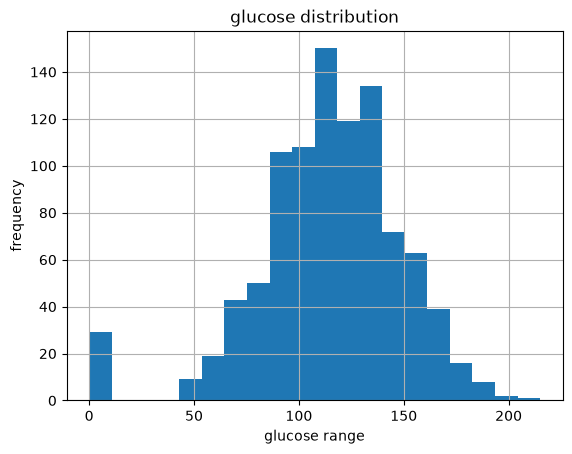

In [220]:
df['glucose'].hist(bins=20)
plt.title('glucose distribution')
plt.xlabel('glucose range')
plt.ylabel('frequency')
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

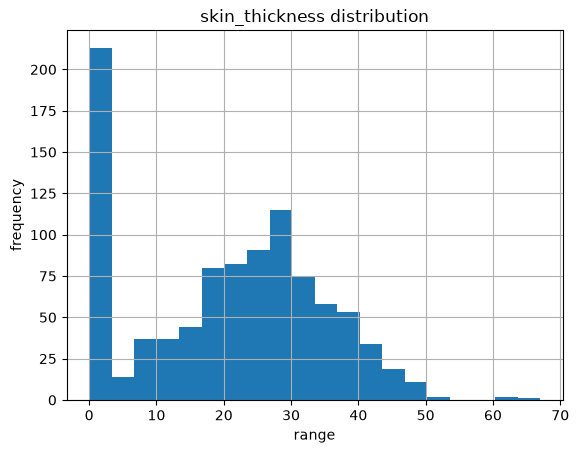

In [221]:
df['skin_thickness'].hist(bins=20)
plt.title('skin_thickness distribution')
plt.xlabel('range')
plt.ylabel('frequency')
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

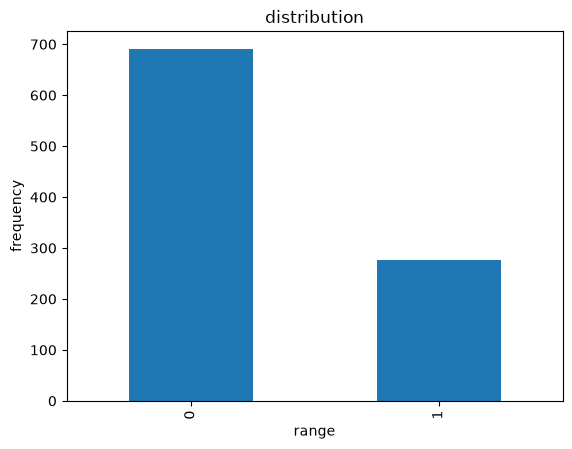

In [222]:
df['outcome'].value_counts().plot(kind="bar")
plt.title('distribution')
plt.xlabel('range')
plt.ylabel('frequency')
plt.show

use boxplot to expose outliers

<function matplotlib.pyplot.show(close=None, block=None)>

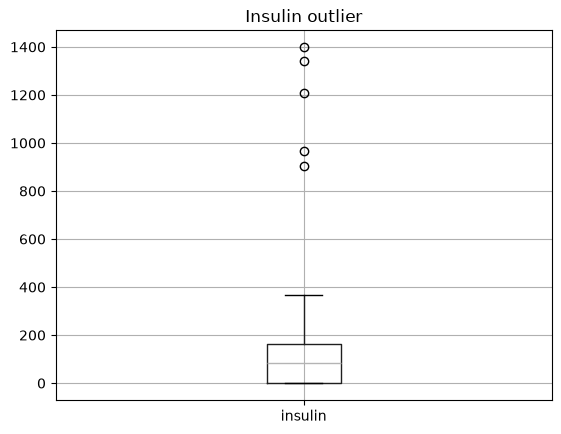

In [223]:
df.boxplot(column='insulin')
plt.title('Insulin outlier')
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

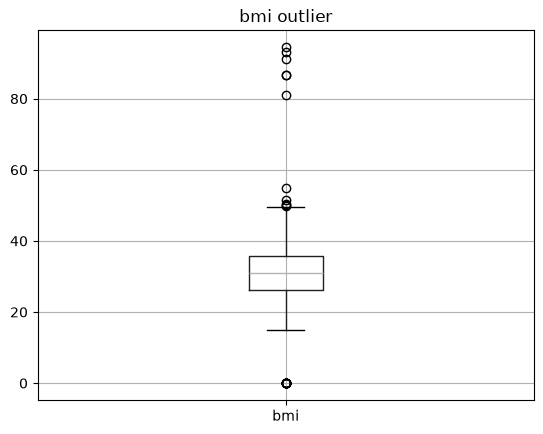

In [224]:
df.boxplot(column='bmi')
plt.title('bmi outlier')
plt.show

DATA CLEANING

count missing values per column

In [225]:
df.isnull().sum()

patient_id            0
age                   9
gender                0
pregnancies           0
glucose               0
blood_pressure        0
skin_thickness        0
insulin               0
bmi                  38
diabetes_pedigree     0
physical_activity    58
smoker               47
last_checkup_date     0
outcome               0
dtype: int64

In [226]:
df.isnull().sum().sum()

np.int64(152)

express missingness as a prpportion


In [227]:
df.isnull().mean()

patient_id           0.000000
age                  0.009298
gender               0.000000
pregnancies          0.000000
glucose              0.000000
blood_pressure       0.000000
skin_thickness       0.000000
insulin              0.000000
bmi                  0.039256
diabetes_pedigree    0.000000
physical_activity    0.059917
smoker               0.048554
last_checkup_date    0.000000
outcome              0.000000
dtype: float64

inspect the affect rows

In [228]:
df[df['physical_activity'].isnull()]

,patient_id,age,gender,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree,physical_activity,smoker,last_checkup_date,outcome
0,P00826,79.0,male,0,124,71,30,0,23.4,0.588,NaN,No,20/04/2023,0
3,P00687,68.0,female,7,121,88,0,0,29.0,1.217,NaN,Y,14/04/2024,1
14,P00462,31.0,female,0,100,0,35,121,27.2,0.498,NaN,NaN,14/01/2023,0
26,P00801,69.0,female,6,116,71,0,52,20.6,0.465,NaN,N,26/04/2024,0
31,P00057,24.0,female,0,117,83,20,230,27.5,0.779,NaN,N,21/06/2024,0
63,P00144,21.0,M,4,107,70,41,178,45.1,0.092,NaN,N,17/06/2024,0
66,P00524,64.0,Male,0,172,68,52,109,93.1,0.311,NaN,Y,01/11/2023,1
100,P00184,29.0,Female,2,145,0,26,142,NaN,0.330,NaN,N,18/12/2024,0
138,P00895,63.0,Female,0,122,83,0,65,30.5,0.677,NaN,N,15/02/2024,1
145,P00795,80.0,Male,5,120,66,0,0,26.2,0.060,NaN,Yes,07/04/2023,1


In [229]:
df[df.isnull().any(axis=1)]

,patient_id,age,gender,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree,physical_activity,smoker,last_checkup_date,outcome
0,P00826,79.0,male,0,124,71,30,0,23.4,0.588,NaN,No,20/04/2023,0
2,P00517,39.0,F,0,142,68,22,159,26.9,0.777,low,NaN,08/07/2023,0
3,P00687,68.0,female,7,121,88,0,0,29.0,1.217,NaN,Y,14/04/2024,1
8,P00929,32.0,Female,6,129,74,0,226,20.6,0.655,High,NaN,15/10/2023,1
10,P00300,61.0,female,0,90,70,14,10,NaN,0.050,low,N,19/02/2023,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
935,P00505,24.0,Male,0,83,67,22,98,NaN,0.726,medium,N,28/02/2024,0
938,P00082,35.0,Female,0,71,93,29,257,17.8,0.985,NaN,N,11/12/2024,0
955,P00622,48.0,female,7,140,82,34,162,27.5,0.885,NaN,Yes,27/07/2023,0
959,P00674,42.0,Female,5,124,71,22,121,NaN,0.400,NaN,N,01/06/2024,0


count the placeholders

In [230]:
(df['glucose']==0).sum()

np.int64(29)

In [231]:
placeholders_cols=['glucose','blood_pressure','skin_thickness','insulin','bmi']
for c in placeholders_cols:
    print(c,'->',(df[c]==0).sum(),'zeros')

glucose -> 29 zeros
blood_pressure -> 48 zeros
skin_thickness -> 213 zeros
insulin -> 269 zeros
bmi -> 18 zeros


convert placeholders to missing values

In [232]:
import numpy as np

In [233]:
before_missing = df.isnull().sum().sum()


In [234]:
df['glucose']=df['glucose'].replace(0,np.nan)

In [235]:
print(df['glucose'])

0      124.0
1      153.0
2      142.0
3      121.0
4      107.0
       ...  
963      NaN
964    140.0
965    130.0
966    123.0
967    114.0
Name: glucose, Length: 968, dtype: float64


In [236]:

for c in placeholders_cols:
    df[c]=df[c].replace(0,np.nan)
after_missing = df.isnull().sum().sum()
print("missing cells before:",before_missing)
print("missing cells after:",after_missing)

missing cells before: 152
missing cells after: 729


In [237]:
df.isnull().sum()

patient_id             0
age                    9
gender                 0
pregnancies            0
glucose               29
blood_pressure        48
skin_thickness       213
insulin              269
bmi                   56
diabetes_pedigree      0
physical_activity     58
smoker                47
last_checkup_date      0
outcome                0
dtype: int64

fill numeric colummns

In [238]:
df['glucose']=df['glucose'].fillna(df['glucose'].median)

In [239]:
print(df['glucose'])

0                                                  124.0
1                                                  153.0
2                                                  142.0
3                                                  121.0
4                                                  107.0
                             ...                        
963    <bound method Series.median of 0      124.0\n1...
964                                                140.0
965                                                130.0
966                                                123.0
967                                                114.0
Name: glucose, Length: 968, dtype: object


In [240]:
col_fill=["age","blood_pressure","skin_thickness","insulin","bmi"]
for i in col_fill:
    df[i]=df[i].fillna(df[i].median())

In [241]:
df.isnull().sum()

patient_id            0
age                   0
gender                0
pregnancies           0
glucose               0
blood_pressure        0
skin_thickness        0
insulin               0
bmi                   0
diabetes_pedigree     0
physical_activity    58
smoker               47
last_checkup_date     0
outcome               0
dtype: int64

fill categorical column

In [242]:
category=["smoker","physical_activity"]
for i in category:
    df[i]=df[i].fillna('unknown')

verify no missing values remain

In [243]:
df[category].isnull().sum()

smoker               0
physical_activity    0
dtype: int64

remove stray whitespace

In [244]:
df.value_counts('gender')

gender
Female     223
Male       207
female     207
F          120
male       118
M           53
Male        12
Female       7
male         7
F            7
female       4
M            3
Name: count, dtype: int64

In [245]:
df['gender'].unique()

<StringArray>
[   'male',    'Male',       'F',  'female',  'Female',       'M', 'female ',
      'M ',   'Male ', 'Female ',   'male ',      'F ']
Length: 12, dtype: str

In [246]:
df['gender']=df['gender'].str.strip()

In [247]:
df['gender'].unique

<bound method Series.unique of 0        male
1        Male
2           F
3      female
4      female
        ...  
963      male
964         F
965    Female
966         F
967      Male
Name: gender, Length: 968, dtype: str>

In [248]:
df.value_counts('gender')

gender
Female    230
Male      219
female    211
F         127
male      125
M          56
Name: count, dtype: int64

In [249]:
for i in category:
    df[i]=df[i].str.strip()

In [250]:
df.value_counts(['physical_activity','smoker'])

physical_activity  smoker 
Medium             N          67
medium             N          67
HIGH               N          61
High               N          58
Low                N          55
low                N          50
Low                No         43
Medium             No         42
HIGH               No         40
High               No         39
low                No         35
medium             No         35
High               Y          32
medium             Y          30
Low                Y          29
low                Y          28
Medium             Yes        25
Low                Yes        23
unknown            N          22
HIGH               Y          22
Medium             Y          19
HIGH               Yes        18
medium             Yes        18
low                Yes        16
unknown            No         15
High               Yes        15
HIGH               unknown    12
unknown            Y          10
High               unknown    10
medium          

In [251]:
df['physical_activity'].unique()

<StringArray>
['unknown', 'medium', 'low', 'Low', 'HIGH', 'Medium', 'High']
Length: 7, dtype: str

In [252]:
df['gender']=df['gender'].str.lower()

In [253]:
df.value_counts('gender')

gender
female    441
male      344
f         127
m          56
Name: count, dtype: int64

In [254]:
df['physical_activity']=df['physical_activity'].str.title()

In [255]:
df.value_counts('physical_activity')

physical_activity
Medium     315
High       307
Low        288
Unknown     58
Name: count, dtype: int64

In [256]:
df['smoker']=df['smoker'].str.upper()

In [257]:
df.value_counts('smoker')

smoker
N          380
NO         249
Y          170
YES        122
UNKNOWN     47
Name: count, dtype: int64

In [258]:
df['gender']=df['gender'].replace({'f': 'female','m': 'male'})